In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --force-reinstall numpy==1.26.4 scipy==1.13.1 scikit-learn==1.5.2

  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached scipy-1.13.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (60 kB)
  Using cached scikit_learn-1.5.2-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (13 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.0 MB)
Using cached scipy-1.13.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (38.2 MB)
Using cached scikit_learn-1.5.2-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (12.9 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
  Attempting uninstall: t

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("online_shoppers_intention.csv")

# Dataset dimensions
print("Dataset Shape:", df.shape)

# First five records
display(df.head())

# Dataset information
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Target distribution
print("\nTarget Distribution:")
print(df["Revenue"].value_counts())

Dataset Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

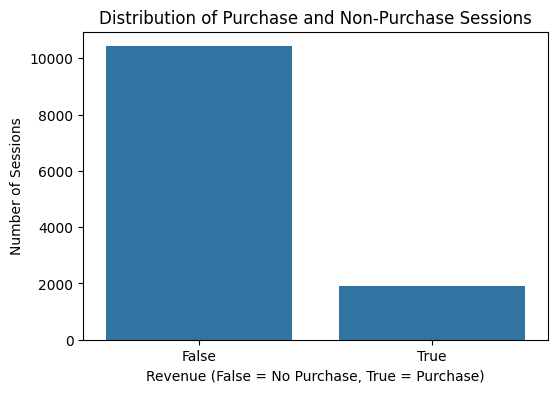

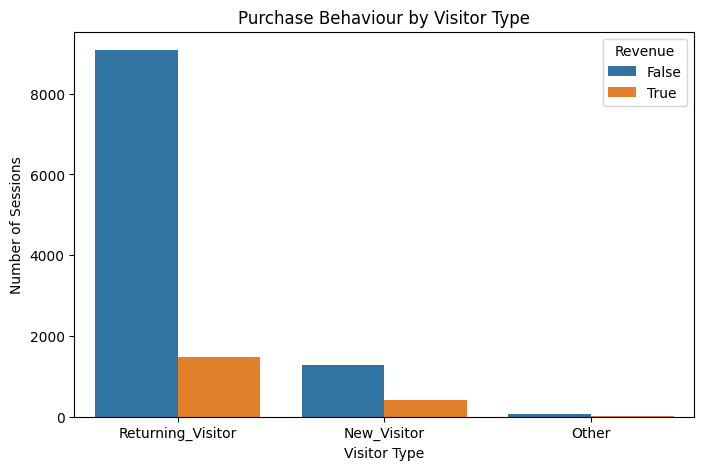

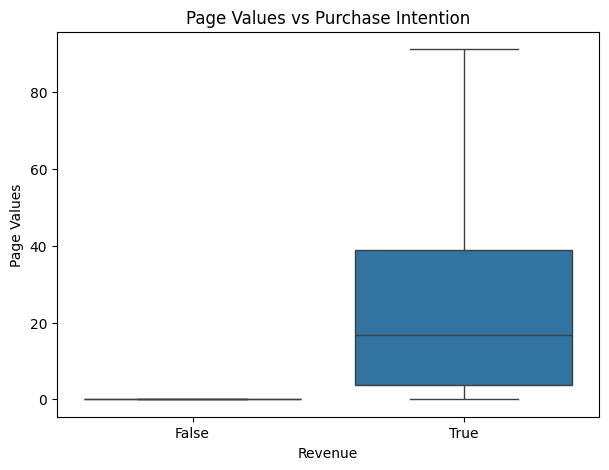

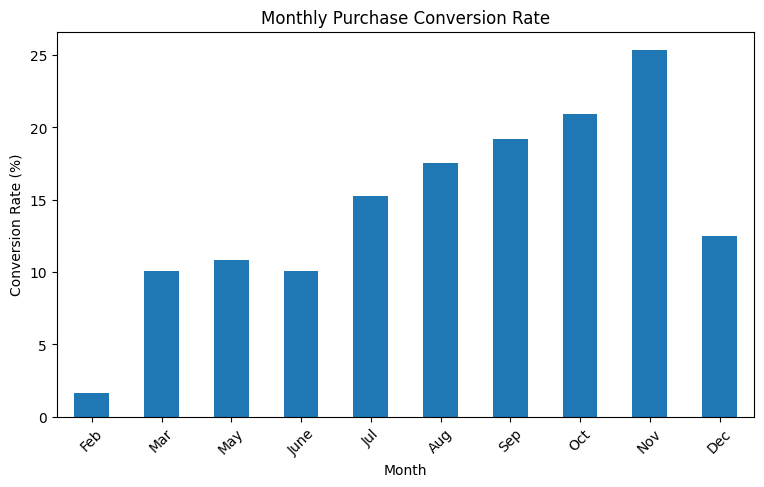

In [4]:

# STEP 2: Exploratory Data Analysis

# 1. Revenue distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Revenue")
plt.title("Distribution of Purchase and Non-Purchase Sessions")
plt.xlabel("Revenue (False = No Purchase, True = Purchase)")
plt.ylabel("Number of Sessions")
plt.show()

# 2. Visitor type vs Revenue
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="VisitorType", hue="Revenue")
plt.title("Purchase Behaviour by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Number of Sessions")
plt.show()

# 3. Page Values vs Revenue
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Revenue", y="PageValues",
            showfliers=False)
plt.title("Page Values vs Purchase Intention")
plt.xlabel("Revenue")
plt.ylabel("Page Values")
plt.show()

# 4. Monthly purchase conversion rate
monthly_conversion = (
    df.groupby("Month")["Revenue"].mean() * 100
)

month_order = [
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_conversion = monthly_conversion.reindex(month_order)

plt.figure(figsize=(9, 5))
monthly_conversion.plot(kind="bar")
plt.title("Monthly Purchase Conversion Rate")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [5]:

# STEP 3: DATA PREPROCESSING

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Remove exact duplicate records
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Dataset shape after removing duplicates:", df_clean.shape)
print("Duplicates removed:", df.shape[0] - df_clean.shape[0])

# 2. Separate features and target
X = df_clean.drop("Revenue", axis=1)
y = df_clean["Revenue"].astype(int)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

# 3. Identify categorical and numerical columns
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType"
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("\nCategorical features:", categorical_features)
print("\nNumerical features:", numerical_features)

# 4. Create preprocessing pipelines
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# 5. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Original dataset shape: (12330, 18)
Dataset shape after removing duplicates: (12205, 18)
Duplicates removed: 125

Feature shape: (12205, 17)
Target shape: (12205,)

Categorical features: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']

Numerical features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend']

Training dataset shape: (9764, 17)
Testing dataset shape: (2441, 17)

Training target distribution:
Revenue
0    84.371159
1    15.628841
Name: proportion, dtype: float64

Testing target distribution:
Revenue
0    84.350676
1    15.649324
Name: proportion, dtype: float64


In [6]:

# Configure preprocessing

numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline configured successfully!")

Preprocessing pipeline configured successfully!


In [7]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Define five classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    )
}

print("All five classification models defined successfully!")

All five classification models defined successfully!


In [8]:

from sklearn.pipeline import Pipeline

results = []
trained_models = {}

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    # Create complete ML pipeline
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Prediction probabilities for AUC
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_prob)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "ML Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

    # Save trained pipeline
    trained_models[model_name] = pipeline

    print(f"{model_name} training completed!")

# Create comparison table
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "MCC": "{:.4f}"
    })
)


Training: Logistic Regression
Logistic Regression training completed!

Training: Decision Tree
Decision Tree training completed!

Training: KNN
KNN training completed!

Training: Naive Bayes
Naive Bayes training completed!

Training: Support Vector Machine
Support Vector Machine training completed!

MODEL PERFORMANCE COMPARISON


,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8873,0.8997,0.7560,0.4136,0.5347,0.5049
1,Decision Tree,0.8546,0.7422,0.5325,0.5785,0.5546,0.4684
2,KNN,0.8746,0.7979,0.6667,0.3979,0.4984,0.4507
3,Naive Bayes,0.2773,0.7509,0.1756,0.9791,0.2978,0.1375
4,Support Vector Machine,0.8951,0.8726,0.7368,0.5131,0.6049,0.5586



MODEL: Logistic Regression


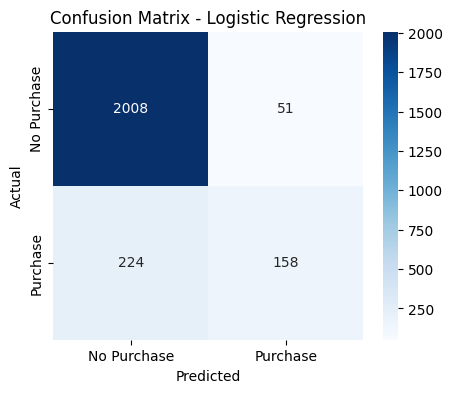


Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.90      0.98      0.94      2059
    Purchase       0.76      0.41      0.53       382

    accuracy                           0.89      2441
   macro avg       0.83      0.69      0.74      2441
weighted avg       0.88      0.89      0.87      2441


MODEL: Decision Tree


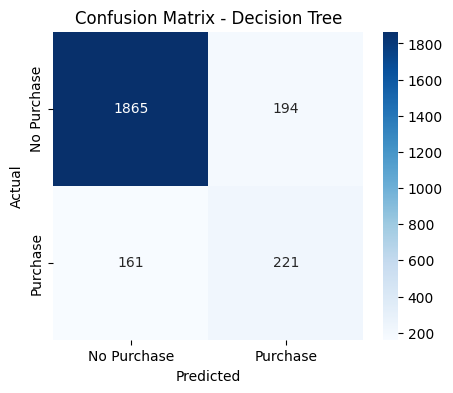


Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.92      0.91      0.91      2059
    Purchase       0.53      0.58      0.55       382

    accuracy                           0.85      2441
   macro avg       0.73      0.74      0.73      2441
weighted avg       0.86      0.85      0.86      2441


MODEL: KNN


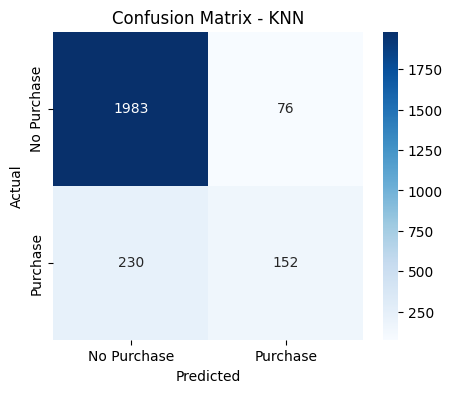


Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.90      0.96      0.93      2059
    Purchase       0.67      0.40      0.50       382

    accuracy                           0.87      2441
   macro avg       0.78      0.68      0.71      2441
weighted avg       0.86      0.87      0.86      2441


MODEL: Naive Bayes


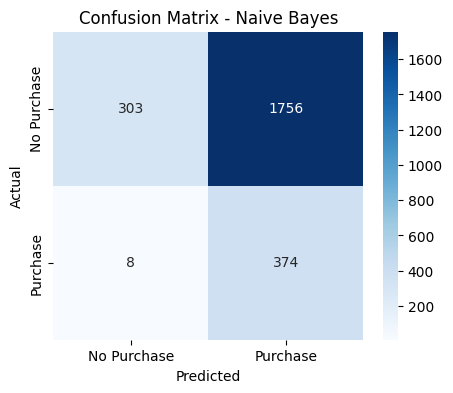


Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.97      0.15      0.26      2059
    Purchase       0.18      0.98      0.30       382

    accuracy                           0.28      2441
   macro avg       0.57      0.56      0.28      2441
weighted avg       0.85      0.28      0.26      2441


MODEL: Support Vector Machine


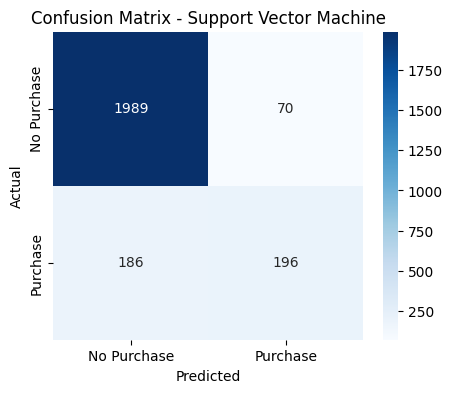


Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.91      0.97      0.94      2059
    Purchase       0.74      0.51      0.60       382

    accuracy                           0.90      2441
   macro avg       0.83      0.74      0.77      2441
weighted avg       0.89      0.90      0.89      2441



In [9]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Generate reports for all five models

for model_name, pipeline in trained_models.items():

    print("\n" + "=" * 60)
    print("MODEL:", model_name)
    print("=" * 60)

    y_pred = pipeline.predict(X_test)

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Purchase", "Purchase"],
        yticklabels=["No Purchase", "Purchase"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # Classification Report
    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No Purchase", "Purchase"],
            zero_division=0
        )
    )

In [10]:

import os
import joblib

# Create models directory
os.makedirs("models", exist_ok=True)

# Save all five trained pipelines
model_files = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "KNN": "knn.pkl",
    "Naive Bayes": "naive_bayes.pkl",
    "Support Vector Machine": "svm.pkl"
}

for model_name, filename in model_files.items():

    joblib.dump(
        trained_models[model_name],
        os.path.join("models", filename)
    )

    print(f"{model_name} saved successfully!")

print("\nAll five models saved!")

Logistic Regression saved successfully!
Decision Tree saved successfully!
KNN saved successfully!
Naive Bayes saved successfully!
Support Vector Machine saved successfully!

All five models saved!


In [11]:

# STEP 5: EXPORT TEST DATA FOR STREAMLIT

# Combine test features and target
test_data = X_test.copy()

test_data["Revenue"] = y_test.map({
    0: False,
    1: True
})

# Save test dataset
test_data.to_csv("test_data.csv", index=False)

print("Test dataset exported successfully!")
print("Test data shape:", test_data.shape)
print("\nFirst five records:")
display(test_data.head())

print("\nTarget distribution:")
print(test_data["Revenue"].value_counts())

Test dataset exported successfully!
Test data shape: (2441, 18)

First five records:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
11757,0,0.000000,0,0.0,12,482.500000,0.02,0.040000,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,False,False
7022,2,287.200000,0,0.0,16,473.283333,0.00,0.002222,0.0,0.0,Oct,2,2,1,2,New_Visitor,True,False
7281,2,187.900000,4,100.1,29,2107.033333,0.00,0.024242,0.0,0.0,Oct,1,1,3,1,Returning_Visitor,False,False
11373,7,280.266667,0,0.0,11,329.683333,0.00,0.023077,0.0,0.0,Dec,2,2,7,2,Returning_Visitor,False,False
4799,0,0.000000,0,0.0,5,0.000000,0.20,0.200000,0.0,0.0,May,3,2,5,6,Returning_Visitor,False,False



Target distribution:
Revenue
False    2059
True      382
Name: count, dtype: int64


In [12]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [ ]:
!streamlit run app.py


      👋 Welcome to Streamlit!

      If you'd like to receive helpful onboarding emails, news, offers, promotions,
      and the occasional swag, please enter your email address below. Otherwise,
      leave this field blank.

      Email:  